In [1]:
import numpy as np
import torch
import torch.nn as nn
import zipfile

In [2]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
torch.manual_seed(42)
np.random.seed(42)

In [4]:
torch.cuda.is_available()

False

# loading data

In [5]:
def load(folder, scanners):
    data = {}
    with zipfile.ZipFile("train_data.zip", "r") as zf:
        for s in scanners:
            X = np.load(zf.open(f"{folder}/scanner{s}_X.npy")).astype(np.float32) / 255.0
            y = np.load(zf.open(f"{folder}/scanner{s}_y.npy")).astype(np.int64)
            data[s] = (X, y)
    return data

d1 = load("subtask1", [1, 2, 3])
d2 = load("subtask2", range(1, 9))

def join(data):
    XX = []
    yy = []
    for sc in data:
        XX.append(data[sc][0])
        yy.append(data[sc][1])
    return np.concatenate(XX), np.concatenate(yy)

# preprocesare

In [6]:
# 14 pt ca e jumate din 28
def prep(x):
    out = x.clone()
    for i in range(x.shape[0]):
        img = out[i]
        lo = img.min()
        hi = img.max()
        img = (img - lo) / (hi - lo + 0.000001)
        for r in [0, 14]:
            for c in [0, 14]:
                q = img[:, r:r+14, c:c+14]
                if float(q.mean()) > 0.5:
                    img[:, r:r+14, c:c+14] = 1 - q
        out[i] = img
    return out

def shift(x):
    dy, dx = np.random.randint(-2, 3, size=2)
    return torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))

# vizualizare

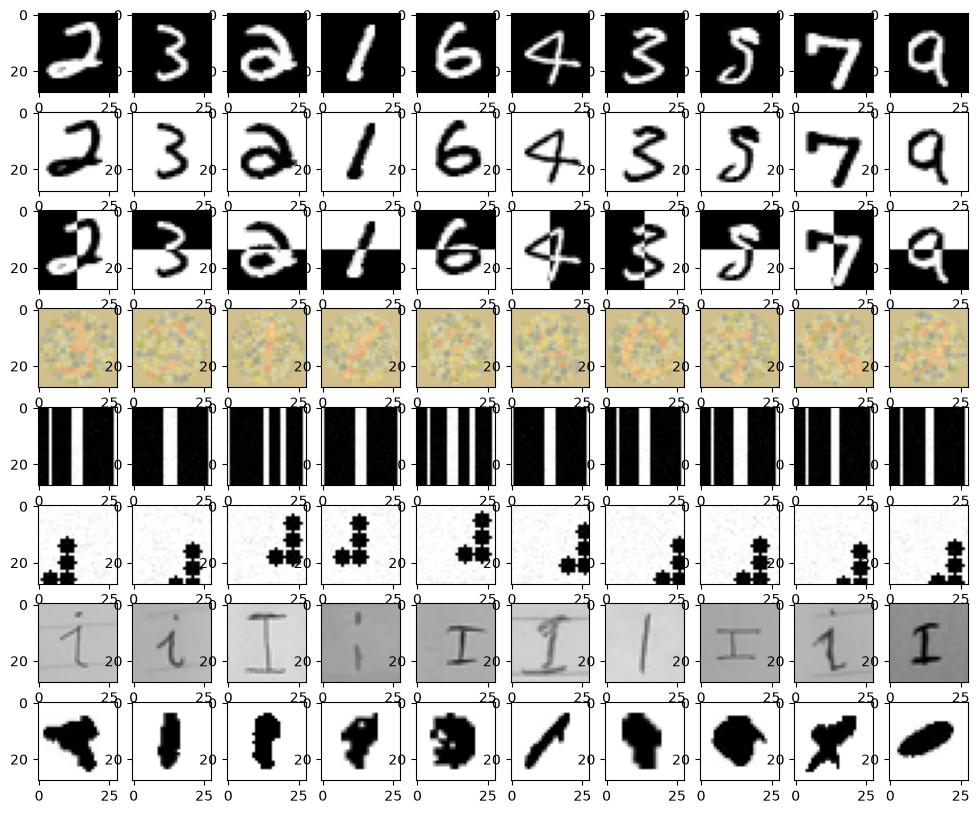

In [7]:
fig, axes = plt.subplots(8, 10, figsize=(12, 10))
for idx in range(1, 9):
    X, y = d2[idx]
    for k in range(10):
        axes[idx-1, k].imshow(X[k].transpose(1, 2, 0))

plt.show()

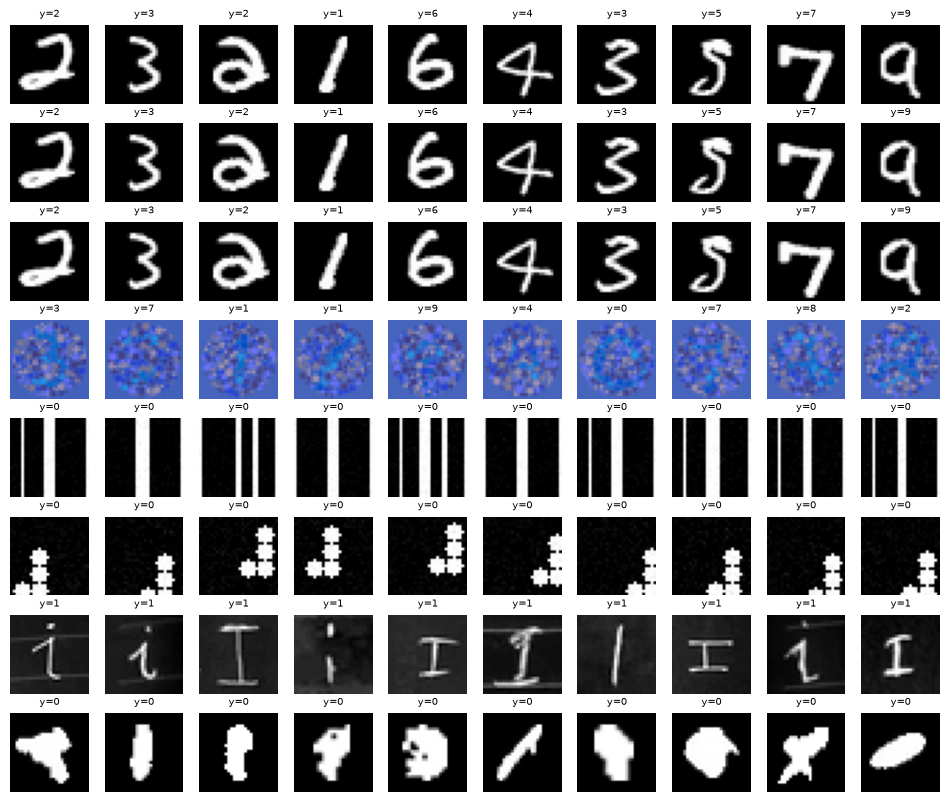

In [8]:
fig, axes = plt.subplots(8, 10, figsize=(12, 10))
for row, s in enumerate(d2):
    X, y = d2[s]
    P = prep(torch.from_numpy(X[:10])).numpy()
    for k in range(10):
        axes[row, k].imshow(P[k].transpose(1, 2, 0))
        axes[row, k].set_title(f"y={y[k]}", fontsize=7)
        axes[row, k].axis("off")
plt.show()

# model

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, in_ch=1, c1=8, c2=16, c3=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, c1, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 28 -> 14
            nn.Conv2d(c1, c2, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 14 -> 7
            nn.Conv2d(c2, c3, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),                                          # (N, c3, 7, 7) -> (N, c3, 1, 1)
            nn.Flatten(),
            nn.Linear(c3, 10),
        )

    def forward(self, x):
        return self.net(prep(x))

In [10]:
class FlatCNN(nn.Module):
    def __init__(self, in_ch=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(16 * 7 * 7, 10),
        )

    def forward(self, x):
        return self.net(prep(x))

In [11]:
def train_model(model, X, y, epochs=10, lr=0.001, batch_size=64, augment=True):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    X_t = prep(torch.from_numpy(X)).to(device)
    y_t = torch.from_numpy(y).long().to(device)

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(y))
        total_loss = 0.0
        for start in range(0, len(y), batch_size):
            idx = perm[start:start + batch_size]
            opt.zero_grad()
            xb = X_t[idx]
            if augment:
                xb = shift(xb)
            loss = loss_fn(model.net(xb), y_t[idx])
            loss.backward()
            opt.step()
            total_loss += loss.item()

        model.eval()
        with torch.no_grad():
            acc = (model(X_t).argmax(1) == y_t).float().mean().item()
        print(f"  epoch {epoch:2d}: loss={total_loss:.4f}  acc={acc:.4f}")

    model.eval()
    return model.cpu()

# validation

In [12]:
def split(data, sp=0.2):
    fit = {}
    val = {}
    for s in data:
        X, y = data[s]
        X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=sp, stratify=y, random_state=0)
        fit[s] = (X_fit, y_fit)
        val[s] = (X_val, y_val)
    return fit, val

In [13]:
def scoremetric(A, P, subtask):
    S = A*100 - P/7500
    if subtask == 1:
        score = max(0, min(30, (S - 90) / 10 * 30))
    else:
        score = max(0, min(70, (S - 65) / 25 * 70))
    return score

def evaluate(model, val, subtask):
    model.eval()
    scores = []
    with torch.no_grad():
        for sc in val:
            X, y = val[sc]
            preds = model(torch.from_numpy(X)).argmax(1).numpy()
            scores.append((preds==y).mean())
            print("scanner", sc, "accuracy", round(scores[-1], 4))
    A = np.mean(scores)
    P = sum(p.numel() for p in model.parameters())
    score = scoremetric(A, P, subtask)
    print("accuracy: ", round(A, 4), "params: ", P, "score: ", round(score, 4))

In [14]:
fit1, val1 = split(d1)
XX = []
yy = []
for sc in fit1:
    X, y = fit1[sc]
    XX.append(X)
    yy.append(y)
    
X_fit = np.concatenate(XX)
y_fit = np.concatenate(yy)

In [15]:
fit1, val1 = split(d1)
X_fit, y_fit = join(fit1)
model1 = train_model(FlatCNN(in_ch=1), X_fit, y_fit, epochs=100)
evaluate(model1, val1, subtask=1)

  epoch  0: loss=43.0015  acc=0.1575
  epoch  1: loss=39.1395  acc=0.6975
  epoch  2: loss=31.3132  acc=0.7150
  epoch  3: loss=23.0434  acc=0.8000
  epoch  4: loss=19.0097  acc=0.8325
  epoch  5: loss=14.9549  acc=0.8575
  epoch  6: loss=14.1169  acc=0.8900
  epoch  7: loss=14.6037  acc=0.9000
  epoch  8: loss=11.2720  acc=0.9075
  epoch  9: loss=9.2087  acc=0.9075
  epoch 10: loss=11.5435  acc=0.9225
  epoch 11: loss=8.8924  acc=0.9225
  epoch 12: loss=8.5529  acc=0.9325
  epoch 13: loss=9.0299  acc=0.9350
  epoch 14: loss=7.7445  acc=0.9425
  epoch 15: loss=7.3791  acc=0.9475
  epoch 16: loss=6.8720  acc=0.9525
  epoch 17: loss=7.6380  acc=0.9500
  epoch 18: loss=5.9868  acc=0.9575
  epoch 19: loss=5.5960  acc=0.9625
  epoch 20: loss=5.5952  acc=0.9750
  epoch 21: loss=4.9911  acc=0.9625
  epoch 22: loss=4.4019  acc=0.9650
  epoch 23: loss=4.3486  acc=0.9700
  epoch 24: loss=4.3540  acc=0.9700
  epoch 25: loss=3.8914  acc=0.9725
  epoch 26: loss=4.1358  acc=0.9750
  epoch 27: loss=3

In [16]:
fit2, val2 = split(d2)
X_fit, y_fit = join(fit2)
model2 = train_model(FlatCNN(in_ch=3), X_fit, y_fit, epochs=100)
evaluate(model2, val2, subtask=2)

  epoch  0: loss=111.9227  acc=0.3653
  epoch  1: loss=96.3384  acc=0.4603
  epoch  2: loss=88.0728  acc=0.5288
  epoch  3: loss=81.5889  acc=0.5512
  epoch  4: loss=74.4752  acc=0.5819
  epoch  5: loss=71.2706  acc=0.6050
  epoch  6: loss=67.4015  acc=0.6025
  epoch  7: loss=67.0753  acc=0.6300
  epoch  8: loss=62.7036  acc=0.6494
  epoch  9: loss=62.3742  acc=0.6553
  epoch 10: loss=61.0779  acc=0.6541
  epoch 11: loss=58.4440  acc=0.6691
  epoch 12: loss=57.7760  acc=0.6606
  epoch 13: loss=56.3975  acc=0.6797
  epoch 14: loss=54.0369  acc=0.6831
  epoch 15: loss=55.8537  acc=0.6856
  epoch 16: loss=53.7248  acc=0.6981
  epoch 17: loss=53.1766  acc=0.6956
  epoch 18: loss=54.6942  acc=0.7016
  epoch 19: loss=51.6356  acc=0.7019
  epoch 20: loss=50.9583  acc=0.7175
  epoch 21: loss=49.6211  acc=0.7241
  epoch 22: loss=50.9809  acc=0.7188
  epoch 23: loss=50.5382  acc=0.7194
  epoch 24: loss=47.4100  acc=0.7169
  epoch 25: loss=47.2940  acc=0.7316
  epoch 26: loss=48.2392  acc=0.7362


# training

In [17]:
# Export Subtask 1 model with jit.script
model1.eval();
script1 = torch.jit.script(model1)
torch.jit.save(script1, "model_sub1.pt")
print(f"Exported model_sub1.pt")

/Users/ecaterina/practice/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Exported model_sub1.pt


/Users/ecaterina/practice/lib/python3.12/site-packages/torch/jit/_serialization.py:89: FutureWarning: `torch.jit.save` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [18]:
# Export Subtask 2 model with jit.script
model2.eval();
script2 = torch.jit.script(model2)
torch.jit.save(script2, "model_sub2.pt")
print(f"Exported model_sub2.pt")

Exported model_sub2.pt


In [19]:
# Make zip submission
with zipfile.ZipFile("submission.zip", "w") as zf:
    zf.write("model_sub1.pt")
    zf.write("model_sub2.pt")
print("Wrote submission.zip!")

Wrote submission.zip!


In [20]:
from pre_judging_script import build_submission

raw = open("submission.zip", "rb").read()
build_submission(raw, test_images_path="test_data.npz", verbose=True)

Subtask 1 model: 9,098 params
Subtask 2 model: 9,242 params


/Users/ecaterina/practice/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Subtask 1: partial acc=0.9321 score=6/30  complete acc=0.9317 score=6/30  params=9,098
Subtask 2: partial acc=0.7396 score=22/70  complete acc=0.7358 score=21/70  params=9,242


,subtaskID,datapointID,answer
0,1,scores,0.932076 0.931667 9098
1,2,scores,0.739610 0.735750 9242
